# Лабораторная работа №1: регрессия (Wine Quality, красное + белое вино)

**Задача:** по химическим характеристикам вина предсказать его оценку `quality`.

**Метрики:** основная — RMSE (порог: RMSE < 0.70), дополнительная — MAE.

> Это вариант на **объединённом** датасете (красное + белое). Основной вариант — только на красном вине: `lab01_red.ipynb`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [2]:
red = pd.read_csv("data/winequality-red.csv", sep=";")
white = pd.read_csv("data/winequality-white.csv", sep=";")

print("Красных вин:", red.shape)
print("Белых вин:", white.shape)
red.head()

Красных вин: (1599, 12)
Белых вин: (4898, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## 1. Объединение данных

Красные и белые вина объединяем в одну таблицу и добавляем признак `is_red` (1 — красное, 0 — белое), чтобы модель знала тип вина: химический состав красных и белых вин сильно отличается.

In [3]:
red["is_red"] = 1
white["is_red"] = 0

df = pd.concat([red, white], ignore_index=True)
print("Размер объединённой таблицы:", df.shape)

Размер объединённой таблицы: (6497, 13)


## 2. Первичный анализ данных (EDA)

### 2.1 Пропуски и дубликаты

In [4]:
print("Пропусков всего:", df.isna().sum().sum())
print("Полных дубликатов строк:", df.duplicated().sum())

Пропусков всего: 0
Полных дубликатов строк: 1177


**Выводы:**
- Пропусков нет — заполнять ничего не нужно.
- Около 1177 строк (~18%) полностью повторяются. Скорее всего, это разные бутылки или партии с одинаковыми результатами анализа и оценкой. Мы их **не удаляем**: скрытая тестовая выборка, вероятно, взята из того же источника и тоже содержит такие объекты. Но нужно помнить: если одинаковые строки попадут и в обучающую, и в тестовую часть, модель сможет их просто «узнать», и оценка качества будет немного завышена.

### 2.2 Основные статистики

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.215307,1.296434,3.80000,6.40000,7.00000,7.70000,15.90000
volatile acidity,6497.0,0.339666,0.164636,0.08000,0.23000,0.29000,0.40000,1.58000
citric acid,6497.0,0.318633,0.145318,0.00000,0.25000,0.31000,0.39000,1.66000
residual sugar,6497.0,5.443235,4.757804,0.60000,1.80000,3.00000,8.10000,65.80000
chlorides,6497.0,0.056034,0.035034,0.00900,0.03800,0.04700,0.06500,0.61100
free sulfur dioxide,6497.0,30.525319,17.749400,1.00000,17.00000,29.00000,41.00000,289.00000
total sulfur dioxide,6497.0,115.744574,56.521855,6.00000,77.00000,118.00000,156.00000,440.00000
density,6497.0,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898
pH,6497.0,3.218501,0.160787,2.72000,3.11000,3.21000,3.32000,4.01000
sulphates,6497.0,0.531268,0.148806,0.22000,0.43000,0.51000,0.60000,2.00000


**Выводы:**
- Признаки имеют **очень разные масштабы**: `density` — около 0.99–1.04, `chlorides` — сотые доли, а `total sulfur dioxide` — до сотен. Это важно для линейной регрессии: без приведения к одному масштабу её коэффициенты нельзя сравнивать между собой. Для деревьев масштаб не важен.
- У `residual sugar`, `chlorides`, `free sulfur dioxide`, `total sulfur dioxide` максимум во много раз больше 75-го перцентиля — есть **выбросы** (редкие очень большие значения).

### 2.3 Распределение целевой переменной quality

quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: count, dtype: int64

Доля оценок 5 и 6: 0.766


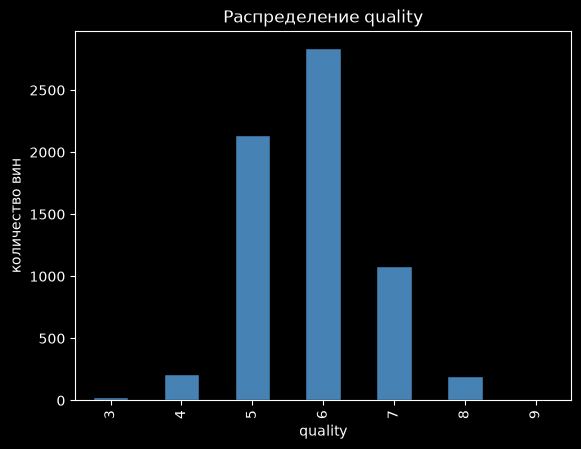

In [6]:
counts = df["quality"].value_counts().sort_index()
print(counts)
print("\nДоля оценок 5 и 6:", round(counts[[5, 6]].sum() / len(df), 3))

counts.plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("Распределение quality")
plt.xlabel("quality")
plt.ylabel("количество вин")
plt.show()

**Выводы:**
- Хотя шкала 0–10, реально встречаются только оценки **3…9**, и около **77% вин имеют оценку 5 или 6**. Очень плохих (3) и отличных (8–9) вин единицы: оценка 9 — всего 5 вин.
- Это сильный **дисбаланс**. Модель, которая минимизирует среднюю ошибку, будет стремиться предсказывать значения около 5–6, потому что там почти все данные. На редких крайних оценках ошибки будут больше.
- Поэтому при разбиении на обучающую и тестовую части важно сохранить доли каждой оценки (стратификация), иначе редкие оценки могут целиком попасть только в одну из частей.

### 2.4 Корреляции признаков с quality

density                -0.306
volatile acidity       -0.266
chlorides              -0.201
is_red                 -0.119
fixed acidity          -0.077
total sulfur dioxide   -0.041
residual sugar         -0.037
pH                      0.020
sulphates               0.038
free sulfur dioxide     0.055
citric acid             0.086
alcohol                 0.444
Name: quality, dtype: float64


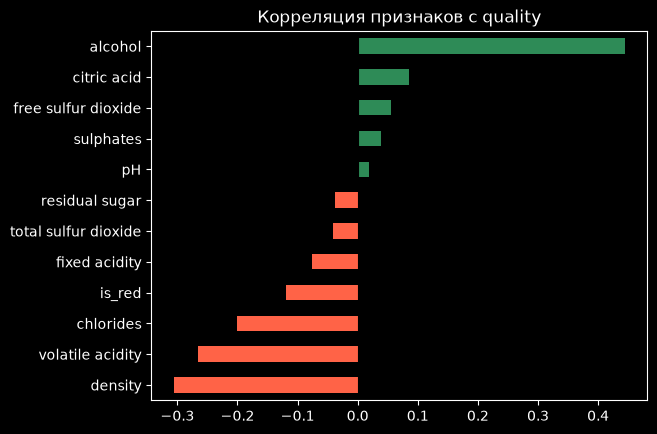

In [7]:
corr_with_target = df.corr()["quality"].drop("quality").sort_values()
print(corr_with_target.round(3))

colors = ["tomato" if v < 0 else "seagreen" for v in corr_with_target]
corr_with_target.plot(kind="barh", color=colors)
plt.title("Корреляция признаков с quality")
plt.axvline(0, color="black", lw=0.8)
plt.show()

**Выводы:**
- **`alcohol` (≈ +0.44)** — самая сильная связь: чем крепче вино, тем в среднем выше оценка. Это осмысленно: из более спелого винограда (больше сахара) после брожения получается больше спирта, такие вина обычно полнее на вкус. Этот признак точно важен для модели.
- **`density` (≈ −0.31)** — плотность физически зависит от спирта (спирт легче воды) и сахара, поэтому эта связь во многом **повторяет** `alcohol` (проверим ниже).
- **`volatile acidity` (≈ −0.27)** — летучая (уксусная) кислотность даёт неприятный уксусный привкус, эксперты снижают оценку.
- **`chlorides` (≈ −0.20)** — солёность тоже снижает оценку.
- Остальные признаки почти не коррелируют с quality (|r| < 0.1). **Но это не значит, что они бесполезны**: корреляция ловит только линейную связь одного признака. Нелинейные зависимости и взаимодействия признаков могут найти деревья.
- Даже самая сильная корреляция умеренная (0.44) → по одному признаку качество хорошо не предсказать, а идеальной точности не будет ни у какой модели.

### 2.5 Корреляции между признаками

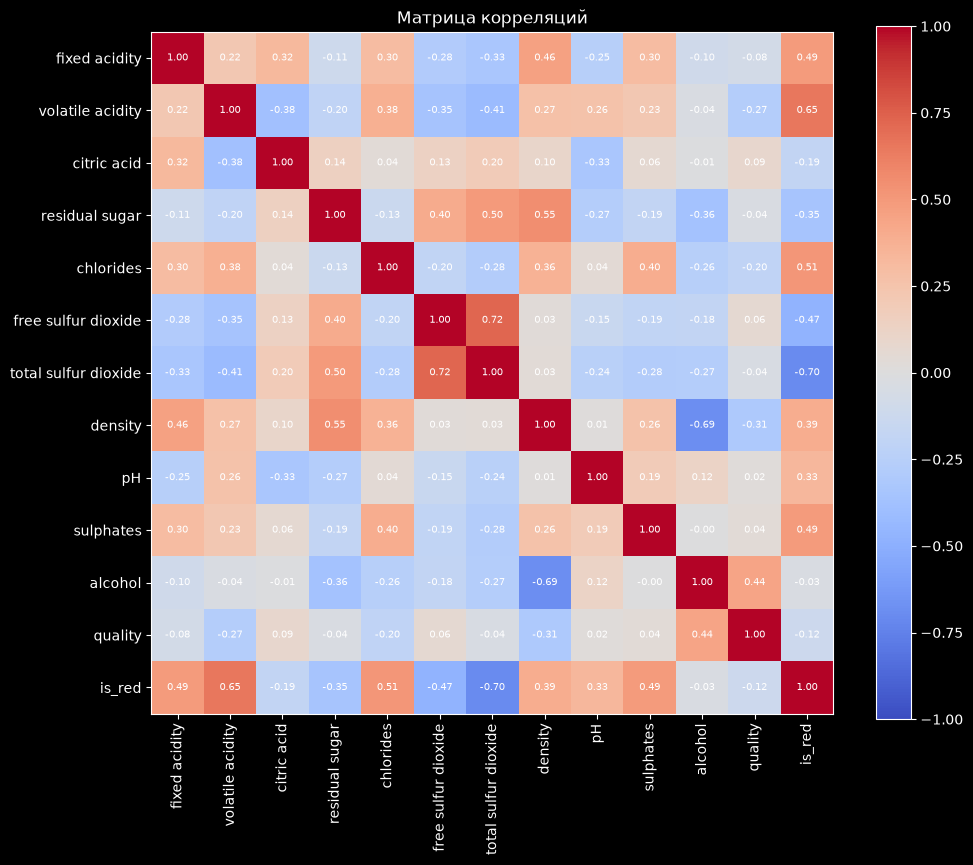

In [8]:
corr = df.corr()
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im)
plt.title("Матрица корреляций")
plt.show()

**Выводы:**
- `density` сильно связана с `alcohol` (≈ −0.69) и `residual sugar` (≈ +0.55): плотность почти целиком определяется спиртом и сахаром. Признаки частично **дублируют** друг друга.
- `free sulfur dioxide` и `total sulfur dioxide` связаны (≈ 0.72): свободный SO₂ — часть общего.
- `is_red` сильно связан с `total sulfur dioxide` (≈ −0.70), `volatile acidity` (≈ +0.65), `chlorides` (≈ +0.51): красные и белые вина химически сильно различаются.
- **Значение для моделирования:** когда признаки сильно связаны между собой (**мультиколлинеарность**), коэффициенты линейной регрессии становятся неустойчивыми и их трудно интерпретировать. На деревья это почти не влияет, но важность может «делиться» между похожими признаками.

### 2.6 Зависимость quality от ключевых признаков

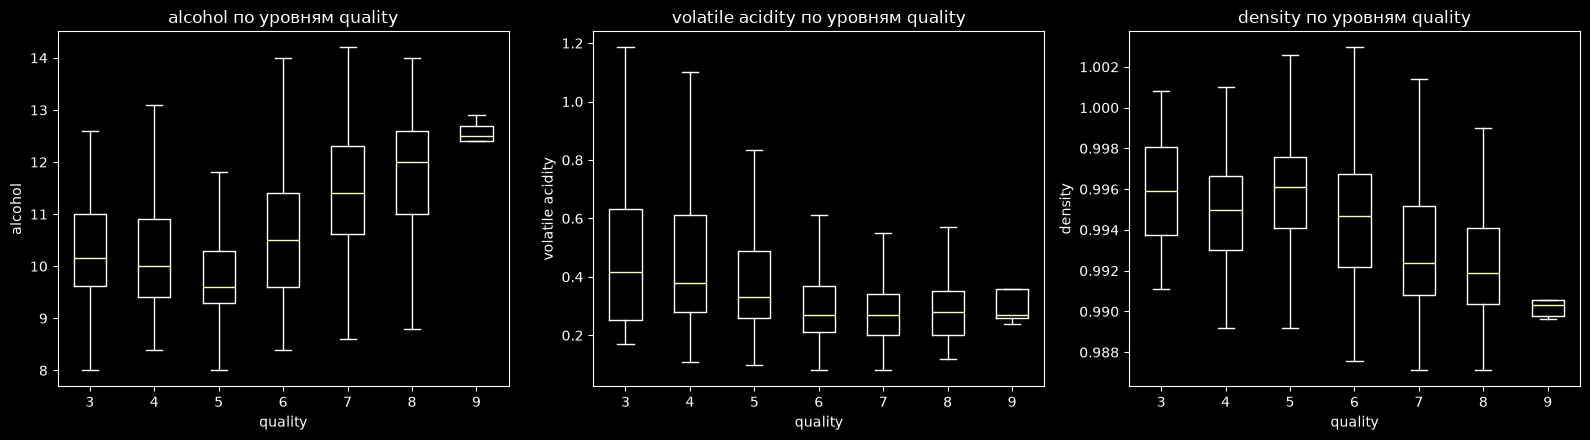

In [9]:
qualities = sorted(df["quality"].unique())
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, feat in zip(axes, ["alcohol", "volatile acidity", "density"]):
    groups = [df.loc[df["quality"] == q, feat] for q in qualities]
    ax.boxplot(groups, showfliers=False)
    ax.set_xticks(range(1, len(qualities) + 1), qualities)
    ax.set_title(f"{feat} по уровням quality")
    ax.set_xlabel("quality")
    ax.set_ylabel(feat)
plt.tight_layout()
plt.show()

**Выводы:**
- Медиана `alcohol` растёт от оценки 5 к 9 — сильная и понятная зависимость. Но от 3 к 5 крепость даже немного *снижается* (минимум — у оценки 5): связь **нелинейная**, с «изломом» около 5. Прямая линия такую форму не опишет, а деревья смогут.
- `volatile acidity` заметно выше у плохих вин (3–4) и снижается с ростом оценки.
- `density` зеркально повторяет `alcohol` — подтверждает, что это во многом тот же сигнал.
- Ящики разных оценок сильно перекрываются: одинаковые значения признака бывают у вин с разными оценками. Плюс оценка субъективна. Значит, в данных есть **неустранимый шум**, и идеальной точности не будет.

### 2.7 Красные vs белые

In [10]:
print(df.groupby("is_red")["quality"].mean().round(3))
print()
print(df.groupby("is_red")[["residual sugar", "total sulfur dioxide", "volatile acidity", "chlorides"]].mean().round(3))

is_red
0    5.878
1    5.636
Name: quality, dtype: float64

        residual sugar  total sulfur dioxide  volatile acidity  chlorides
is_red                                                                   
0                6.391               138.361             0.278      0.046
1                2.539                46.468             0.528      0.087


**Выводы:** средняя оценка у белых чуть выше (≈5.88 против ≈5.64). Химический состав сильно отличается: у белых в разы больше сахара (≈6.4 против ≈2.5 г/л) и SO₂ (≈138 против ≈46 мг/л), у красных выше летучая кислотность и хлориды. Значит, влияние одного и того же признака может зависеть от типа вина (**взаимодействие признаков**). Признак `is_red` оставляем.

## 3. Разбиение на обучающую и тестовую выборки

- **Размер:** 80% train / 20% test (≈5197 / 1300 вин). Данных немного (6.5 тыс.), поэтому большую часть отдаём на обучение, а 1300 объектов в тесте достаточно для стабильной оценки.
- **Способ:** случайное разбиение со **стратификацией по quality** (`stratify=y`): доли каждой оценки в train и test одинаковые. Это важно из-за сильного дисбаланса — иначе редкие оценки (3, 9) могли бы целиком попасть в одну часть.
- `random_state=42` — разбиение одинаковое при каждом запуске (воспроизводимость).
- `quality` удаляется из признаков X — иначе модель «увидела бы ответ».

**Тест используется только один раз — для финальной оценки.** Все решения (выбор моделей, параметров) принимаются по кросс-валидации на train.

**Почему нельзя многократно оценивать модели на одном тесте:** если перебирать варианты и каждый раз смотреть на тест, мы фактически подбираем модель под эти конкретные 1300 вин. Результат на тесте становится оптимистично завышенным, а на новых данных модель покажет себя хуже — это переобучение на тестовую выборку.

In [11]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["quality"])
y = df["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)

pd.DataFrame({
    "train": y_train.value_counts(normalize=True).sort_index(),
    "test": y_test.value_counts(normalize=True).sort_index(),
}).round(3)

Train: (5197, 12)  Test: (1300, 12)


,train,test
quality,,
3,0.005,0.005
4,0.033,0.033
5,0.329,0.329
6,0.437,0.436
7,0.166,0.166
8,0.030,0.030
9,0.001,0.001


Для честного сравнения моделей используем 5-фолдовую кросс-валидацию **только на train**, а также функции для подсчёта метрик.

In [12]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_error

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def evaluate(y_true, y_pred):
    return {"RMSE": rmse(y_true, y_pred), "MAE": mean_absolute_error(y_true, y_pred)}

def cv_rmse(model):
    scores = cross_val_score(model, X_train, y_train, cv=cv,
                             scoring="neg_root_mean_squared_error")
    return -scores.mean()

results = {}

## 4. Метрики и Baseline

**MAE** (Mean Absolute Error) — средняя абсолютная ошибка: на сколько баллов quality модель ошибается в среднем. Все ошибки весят пропорционально своей величине.

**RMSE** (Root Mean Squared Error) — корень из средней квадратичной ошибки, тоже в баллах quality, но ошибки сначала возводятся в квадрат.

**Почему RMSE сильнее реагирует на большие ошибки:** из-за квадрата. Ошибка 0.5 даёт вклад 0.25, а ошибка 2 — вклад 4: в 4 раза большая ошибка весит в 16 раз больше.

**Почему MAE и RMSE одной модели могут заметно различаться:** всегда RMSE ≥ MAE. Если все ошибки примерно одинаковые — RMSE ≈ MAE. Если большинство ошибок маленькие, но есть редкие большие промахи — RMSE заметно больше MAE.

### Baseline
Предсказываем **одну константу для всех вин**. Для RMSE оптимальная константа — **среднее** значение y (сумма квадратов отклонений минимальна в среднем; для MAE оптимальной была бы медиана). Среднее считаем **только по train** — иначе информация из теста попала бы в решение.

In [13]:
const = y_train.mean()
print("Константа (среднее quality на train):", round(const, 4))

y_pred_base = np.full(len(y_test), const)
results["Baseline (mean)"] = evaluate(y_test, y_pred_base)
results["Baseline (mean)"]

Константа (среднее quality на train): 5.8182


{'RMSE': np.float64(0.8737719774992919), 'MAE': 0.6860885718091798}

**Вывод:** константа даёт RMSE ≈ 0.87 — это «ничего не знающая» модель. Любая обученная модель должна быть заметно лучше, иначе она не извлекает из признаков полезной информации. Порог задания 0.70 означает, что нужно уменьшить ошибку baseline примерно на 20%.

## 5. Линейная регрессия

Модель: $\hat y = w_0 + w_1 x_1 + \dots + w_d x_d$, веса подбираются минимизацией MSE на train.

**Нужно ли масштабирование?** На *качество* обычной линейной регрессии масштабирование не влияет. Но оно критично для **интерпретации коэффициентов**: без него коэффициент — это изменение quality при изменении признака на 1 единицу, а «1 единица» у `density` и у `total sulfur dioxide` — несравнимые вещи. После `StandardScaler` коэффициент означает изменение quality при изменении признака на одно стандартное отклонение, и коэффициенты можно сравнивать.

`StandardScaler` встроен в `Pipeline`, поэтому среднее и std считаются **только по train** (и внутри каждого фолда CV — только по обучающей части). Так нет утечки информации из теста.

In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression

lin_reg = make_pipeline(StandardScaler(), LinearRegression())

print("CV RMSE (train, 5 фолдов):", round(cv_rmse(lin_reg), 4))

lin_reg.fit(X_train, y_train)
y_pred_lr = lin_reg.predict(X_test)
results["Linear Regression"] = evaluate(y_test, y_pred_lr)

print("Train RMSE:", round(rmse(y_train, lin_reg.predict(X_train)), 4))
print("Test:", {k: round(float(v), 4) for k, v in results["Linear Regression"].items()})

CV RMSE (train, 5 фолдов): 0.7377
Train RMSE: 0.7337
Test: {'RMSE': 0.728, 'MAE': 0.5678}


citric acid            -0.014
chlorides              -0.022
free sulfur dioxide     0.086
pH                      0.088
total sulfur dioxide   -0.091
sulphates               0.109
fixed acidity           0.112
is_red                  0.134
volatile acidity       -0.242
alcohol                 0.256
residual sugar          0.309
density                -0.323
dtype: float64


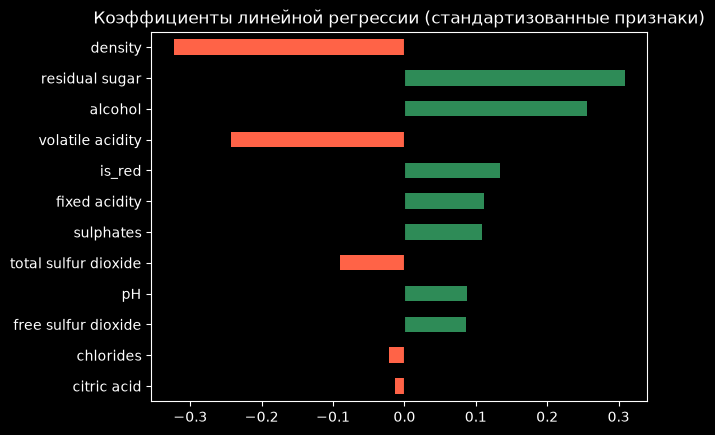

In [15]:
coefs = pd.Series(lin_reg.named_steps["linearregression"].coef_, index=X.columns)
coefs = coefs.reindex(coefs.abs().sort_values().index)
print(coefs.round(3))

colors = ["tomato" if v < 0 else "seagreen" for v in coefs]
coefs.plot(kind="barh", color=colors)
plt.title("Коэффициенты линейной регрессии (стандартизованные признаки)")
plt.axvline(0, color="black", lw=0.8)
plt.show()

**Анализ линейной регрессии:**
- RMSE ≈ 0.73 — лучше baseline (0.87), значит модель извлекает информацию из признаков. Но **порог 0.70 не пройден** — попробуем улучшить линейную модель в разделе 5.1.
- Train RMSE (0.73), CV RMSE (0.74) и Test RMSE (0.73) почти одинаковы — модель **не переобучена**, она скорее **недообучена**: прямая линия слишком простая для этих данных.
- Наибольшие по модулю коэффициенты: `density` (−), `residual sugar` (+), `alcohol` (+), `volatile acidity` (−).
- `alcohol` (+) и `volatile acidity` (−) совпадают с EDA и здравым смыслом.
- Большие коэффициенты у `density` и `residual sugar` — следствие **мультиколлинеарности**: плотность почти линейно выражается через спирт и сахар, поэтому модель использует их «в паре» с противоположными знаками, компенсируя друг друга. Это не значит, что сахар сам по себе сильно повышает оценку (его корреляция с quality ≈ −0.04!). При коррелированных признаках коэффициенты нельзя напрямую читать как «силу влияния».
- **Почему качество ограничено:** зависимость quality от признаков нелинейная (излом по alcohol около 5), есть взаимодействия (красное/белое) — линейная модель этого не видит.

### 5.1 Улучшение линейной регрессии: преобразования и полиномиальные признаки

Идеи из статьи про нелинейные преобразования ([dmitrymakarov.ru/data/transform-02](https://www.dmitrymakarov.ru/data/transform-02/)) и подсказки преподавателя:
- **Yeo-Johnson** (`PowerTransformer`): подбирает для каждого признака степенное преобразование, чтобы «сжать» длинные хвосты (`residual sugar`, `chlorides`, SO₂) и сделать распределение ближе к нормальному. Работает и с нулями (в отличие от Box-Cox). Заодно стандартизирует признаки.
- **Полиномиальные признаки 2-й степени** (`PolynomialFeatures`): квадраты и попарные произведения признаков (`alcohol²`, `alcohol × is_red` и т.д.) — линейная модель получает возможность описывать кривые зависимости и взаимодействия. Признаков становится много (12 → 90), поэтому добавляем **Ridge**-регуляризацию (штраф за большие веса).
- **Отдельная модель для каждого типа вина:** у красных и белых вин разная химия, и одна общая формула описывает обе группы плохо. Обучаем две линейные модели — на красных и на белых — и каждое вино предсказываем «своей» моделью.

Все преобразования встроены в `Pipeline` → их параметры подбираются **только на train**. Варианты и `alpha` выбираем **по CV на train**.

In [16]:
from sklearn.preprocessing import PowerTransformer, PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.base import BaseEstimator, RegressorMixin, clone


class PerWineType(BaseEstimator, RegressorMixin):
    """Отдельная копия модели base для красных (is_red=1) и для белых (is_red=0) вин."""

    def __init__(self, base):
        self.base = base

    def fit(self, X, y):
        self.models_ = {}
        for t in (0, 1):
            mask = X["is_red"] == t
            self.models_[t] = clone(self.base).fit(X[mask].drop(columns="is_red"), y[mask])
        return self

    def predict(self, X):
        pred = np.zeros(len(X))
        for t, model in self.models_.items():
            mask = (X["is_red"] == t).values
            if mask.any():
                pred[mask] = model.predict(X[mask].drop(columns="is_red"))
        return pred


def poly_ridge(alpha):
    return make_pipeline(PowerTransformer(), PolynomialFeatures(degree=2, include_bias=False),
                         StandardScaler(), Ridge(alpha=alpha))


lr_candidates = {
    "1) без преобразований": make_pipeline(StandardScaler(), LinearRegression()),
    "2) Yeo-Johnson": make_pipeline(PowerTransformer(), LinearRegression()),
    "3) Yeo-Johnson + полином. 2 ст. + Ridge(alpha=10)": poly_ridge(10),
    "4) отдельно по типу вина: линейная": PerWineType(make_pipeline(StandardScaler(), LinearRegression())),
}
for alpha in [50, 200, 500]:
    lr_candidates[f"5) отдельно по типу вина: Yeo-Johnson + полином. 2 ст. + Ridge(alpha={alpha})"] = PerWineType(poly_ridge(alpha))

lr_cv = {}
for name, m in lr_candidates.items():
    lr_cv[name] = cv_rmse(m)
    train_score = rmse(y_train, m.fit(X_train, y_train).predict(X_train))
    print(f"{name:80s} CV RMSE = {lr_cv[name]:.4f}   (train RMSE = {train_score:.4f})")

1) без преобразований                                                            CV RMSE = 0.7377   (train RMSE = 0.7337)
2) Yeo-Johnson                                                                   CV RMSE = 0.7415   (train RMSE = 0.7378)
3) Yeo-Johnson + полином. 2 ст. + Ridge(alpha=10)                                CV RMSE = 0.7004   (train RMSE = 0.6875)
4) отдельно по типу вина: линейная                                               CV RMSE = 0.7335   (train RMSE = 0.7267)
5) отдельно по типу вина: Yeo-Johnson + полином. 2 ст. + Ridge(alpha=50)         CV RMSE = 0.6998   (train RMSE = 0.6772)
5) отдельно по типу вина: Yeo-Johnson + полином. 2 ст. + Ridge(alpha=200)        CV RMSE = 0.6986   (train RMSE = 0.6789)
5) отдельно по типу вина: Yeo-Johnson + полином. 2 ст. + Ridge(alpha=500)        CV RMSE = 0.6995   (train RMSE = 0.6823)


In [17]:
best_lr_name = min(lr_cv, key=lr_cv.get)
print("Выбран вариант (по CV на train):", best_lr_name)

lin_reg_best = lr_candidates[best_lr_name]
lin_reg_best.fit(X_train, y_train)
y_pred_lr_best = lin_reg_best.predict(X_test)
results["Linear Regression (улучшенная)"] = evaluate(y_test, y_pred_lr_best)

print("Train RMSE:", round(rmse(y_train, lin_reg_best.predict(X_train)), 4))
print("Test:", {k: round(float(v), 4) for k, v in results["Linear Regression (улучшенная)"].items()})

Выбран вариант (по CV на train): 5) отдельно по типу вина: Yeo-Johnson + полином. 2 ст. + Ridge(alpha=200)
Train RMSE: 0.6789
Test: {'RMSE': 0.697, 'MAE': 0.5473}


**Выводы:**
- **Yeo-Johnson в одиночку не помогает** на общем датасете (CV 0.738 → 0.742): «выпрямление» отдельных признаков не решает главную проблему — красные и белые вина описываются разными зависимостями.
- **Полиномиальные признаки** дают заметный выигрыш (CV ≈ 0.700): произведения вида `признак × is_red` фактически позволяют модели иметь разные коэффициенты для красных и белых, а квадраты описывают изгибы (например, излом по `alcohol`).
- **Отдельная линейная модель для каждого типа вина** без полиномов почти не помогает (CV 0.734), а вместе с Yeo-Johnson, полиномами и Ridge даёт лучший результат по CV (≈0.699); на тесте RMSE ≈ 0.697 — **порог 0.70 пройден, но впритык**.
- При слабой регуляризации полиномиальная модель на train заметно лучше, чем на CV — признак начинающегося **переобучения**; Ridge с подобранным `alpha` это сдерживает.
- **Вывод:** на смеси красных и белых вин линейная модель упирается в ≈0.70 даже с преобразованиями. На одном красном вине (`lab01_red.ipynb`) обычная линейная регрессия даёт ≈0.64 — зависимости внутри одного типа вина проще.

## 6. Random Forest Regressor

Случайный лес — среднее предсказаний многих решающих деревьев. Каждое дерево учится на бутстрэп-подвыборке объектов и в каждом разбиении рассматривает случайное подмножество признаков. Отдельное глубокое дерево сильно переобучается (большая дисперсия), но усреднение многих *разных* деревьев эту дисперсию сильно уменьшает. Деревья естественно ловят нелинейности и взаимодействия признаков, масштабирование им не нужно.

Используем 500 деревьев (больше деревьев — стабильнее результат, переобучения от числа деревьев в лесу нет).

In [18]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1)

print("CV RMSE (train, 5 фолдов):", round(cv_rmse(rf), 4))

rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
results["Random Forest"] = evaluate(y_test, y_pred_rf)

print("Train RMSE:", round(rmse(y_train, rf.predict(X_train)), 4))
print("Test:", {k: round(float(v), 4) for k, v in results["Random Forest"].items()})

CV RMSE (train, 5 фолдов): 0.6226
Train RMSE: 0.223
Test: {'RMSE': 0.6054, 'MAE': 0.4301}


is_red                  0.001
density                 0.057
citric acid             0.058
fixed acidity           0.058
chlorides               0.063
pH                      0.070
total sulfur dioxide    0.073
residual sugar          0.075
sulphates               0.077
free sulfur dioxide     0.088
volatile acidity        0.131
alcohol                 0.248
dtype: float64


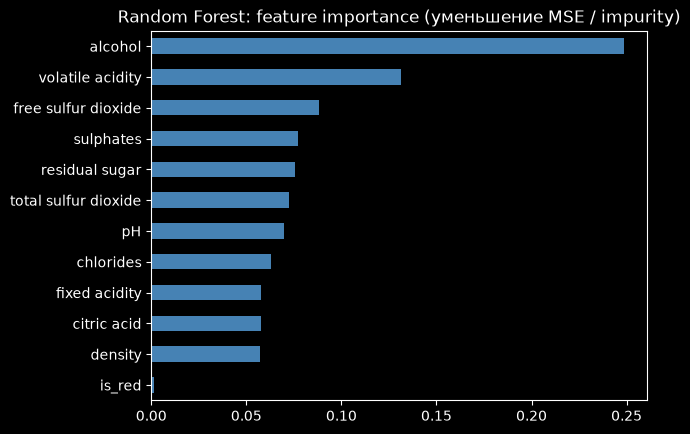

In [19]:
rf_imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
print(rf_imp.round(3))
rf_imp.plot(kind="barh", color="steelblue")
plt.title("Random Forest: feature importance (уменьшение MSE / impurity)"); plt.show()

**Анализ Random Forest:**
- RMSE ≈ 0.61 — значительно лучше линейной регрессии и baseline, **порог 0.70 пройден**.
- Train RMSE ≈ 0.23 намного ниже тестового: лес почти «запоминает» обучающие объекты. Это нормально для леса (глубокие деревья), а честная оценка обобщающей способности — CV и test, они согласуются (≈0.62 и ≈0.61).
- Отчасти высокое качество леса связано с **дубликатами**: одинаковые вина в train и test лес предсказывает почти точно.
- **Важность признаков:** на 1-м месте `alcohol` (≈0.25), на 2-м `volatile acidity` (≈0.13) — ровно то, что показал EDA (две самые «осмысленные» корреляции). Дальше важности примерно равны (0.06–0.09): `free sulfur dioxide`, `sulphates`, `residual sugar` и др.
- Сравнение с линейной регрессией: у леса `density` — один из **наименее** важных признаков, а у линейной модели был самым большим коэффициентом. Причина — лес берёт ту же информацию напрямую из `alcohol` и `residual sugar`, а линейной модели `density` была нужна для компенсации коллинеарности. `is_red` почти не важен: информация о типе вина уже «зашита» в химических признаках (SO₂, хлориды).
- `free sulfur dioxide` и `sulphates` оказались важнее, чем можно было ожидать по корреляции (≈0.05) — значит, их связь с quality **нелинейная** (например, и слишком мало, и слишком много SO₂ плохо).

## 7. Gradient Boosting Regressor

Градиентный бустинг строит деревья **последовательно**: каждое новое (неглубокое) дерево учится исправлять ошибки (остатки / антиградиент функции потерь) уже построенного ансамбля; вклад каждого дерева умножается на `learning_rate`. Лес уменьшает дисперсию усреднением, а бустинг уменьшает **смещение**, шаг за шагом приближаясь к сложной зависимости.

Гиперпараметры выбираем по **CV на train** (тест не трогаем). Сравним настройки по умолчанию (100 деревьев глубины 3) и более мощную конфигурацию: больше деревьев с меньшим шагом, глубже деревья, `subsample=0.8` (каждое дерево на 80% объектов — стохастический бустинг, работает как регуляризация).

In [20]:
from sklearn.ensemble import GradientBoostingRegressor

gb_candidates = {
    "default (100 деревьев, depth=3, lr=0.1)": GradientBoostingRegressor(random_state=RANDOM_STATE),
    "500 деревьев, depth=5, lr=0.05, subsample=0.8": GradientBoostingRegressor(
        n_estimators=500, learning_rate=0.05, max_depth=5, subsample=0.8,
        min_samples_leaf=5, random_state=RANDOM_STATE),
    "1000 деревьев, depth=6, lr=0.03, subsample=0.8": GradientBoostingRegressor(
        n_estimators=1000, learning_rate=0.03, max_depth=6, subsample=0.8,
        min_samples_leaf=5, random_state=RANDOM_STATE),
}

for name, model in gb_candidates.items():
    print(f"{name:50s} CV RMSE = {cv_rmse(model):.4f}")

default (100 деревьев, depth=3, lr=0.1)            CV RMSE = 0.6886
500 деревьев, depth=5, lr=0.05, subsample=0.8      CV RMSE = 0.6422
1000 деревьев, depth=6, lr=0.03, subsample=0.8     CV RMSE = 0.6312


Выбираем конфигурацию с **наименьшим CV RMSE** (решение принято только по train). Дефолтный бустинг заметно хуже: 100 неглубоких деревьев не успевают выучить сложную зависимость (недообучение). Более глубокие деревья с маленьким шагом и subsample дают результат на уровне леса.

In [21]:
cv_scores_gb = {name: cv_rmse(m) for name, m in gb_candidates.items()}
best_gb_name = min(cv_scores_gb, key=cv_scores_gb.get)
print("Выбрана конфигурация:", best_gb_name)

gb = gb_candidates[best_gb_name]
gb.fit(X_train, y_train)
y_pred_gb = gb.predict(X_test)
results["Gradient Boosting"] = evaluate(y_test, y_pred_gb)

print("Train RMSE:", round(rmse(y_train, gb.predict(X_train)), 4))
print("Test:", {k: round(float(v), 4) for k, v in results["Gradient Boosting"].items()})

Выбрана конфигурация: 1000 деревьев, depth=6, lr=0.03, subsample=0.8
Train RMSE: 0.2394
Test: {'RMSE': 0.6034, 'MAE': 0.4385}


is_red                  0.001
fixed acidity           0.057
citric acid             0.058
chlorides               0.062
pH                      0.069
density                 0.069
sulphates               0.076
residual sugar          0.080
total sulfur dioxide    0.082
free sulfur dioxide     0.089
volatile acidity        0.128
alcohol                 0.230
dtype: float64


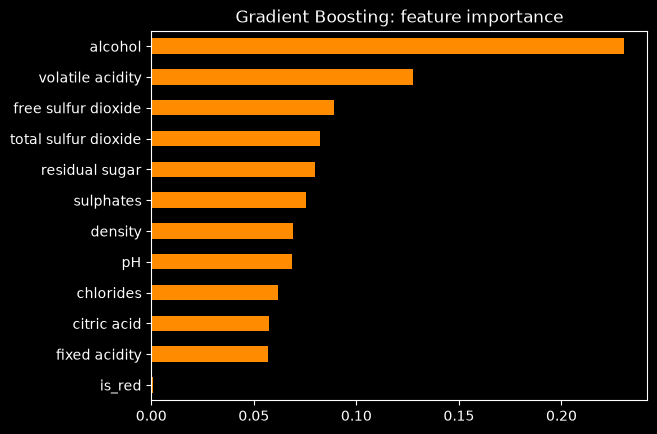

In [22]:
gb_imp = pd.Series(gb.feature_importances_, index=X.columns).sort_values()
print(gb_imp.round(3))
gb_imp.plot(kind="barh", color="darkorange")
plt.title("Gradient Boosting: feature importance"); plt.show()

**Анализ Gradient Boosting:**
- После подбора параметров по CV RMSE ≈ 0.60 — на уровне Random Forest, порог пройден.
- Важность признаков у бустинга почти совпадает с лесом: `alcohol` на первом месте, `volatile acidity` — на втором, затем `free sulfur dioxide`, `total sulfur dioxide`, `residual sugar`. `is_red` — наименее важен.
- Небольшие отличия от леса (например, `density` и `total sulfur dioxide` у бустинга чуть важнее) объясняются тем, что при сильно коррелированных признаках модели могут «выбирать» разные из них для одних и тех же разбиений — важность делится между дублирующими признаками по-разному.

## 8. Честное сравнение моделей

In [23]:
results_df = pd.DataFrame(results).T[["RMSE", "MAE"]].round(4)
results_df["RMSE < 0.70"] = results_df["RMSE"] < 0.70
results_df["лучше baseline"] = results_df["RMSE"] < results_df.loc["Baseline (mean)", "RMSE"]
results_df

,RMSE,MAE,RMSE < 0.70,лучше baseline
Baseline (mean),0.8738,0.6861,False,False
Linear Regression,0.7280,0.5678,False,True
Linear Regression (улучшенная),0.6970,0.5473,True,True
Random Forest,0.6054,0.4301,True,True
Gradient Boosting,0.6034,0.4385,True,True


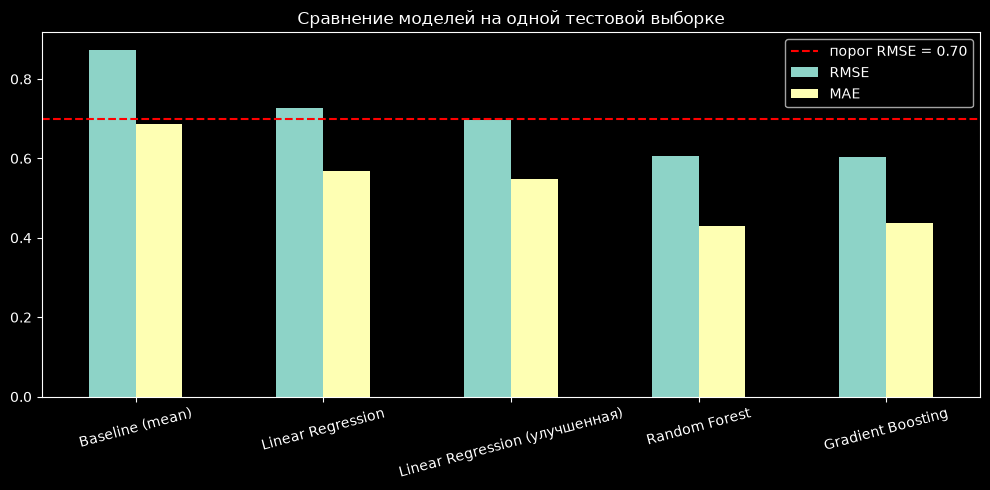

In [24]:
results_df[["RMSE", "MAE"]].plot(kind="bar", rot=15, figsize=(10, 5))
plt.axhline(0.70, color="red", ls="--", label="порог RMSE = 0.70")
plt.legend(); plt.title("Сравнение моделей на одной тестовой выборке"); plt.tight_layout()
plt.show()

**Выводы по сравнению.** Все модели обучены на одном и том же train и оценены на одном и том же test (одно разбиение с `random_state=42`), гиперпараметры выбирались по CV на train — сравнение честное.

- **Baseline превзошли все три модели** → признаки действительно содержат информацию о качестве.
- **Линейная регрессия** (RMSE ≈ 0.73) улучшает baseline лишь на ~17% и не проходит порог 0.70. Причины: (1) связь quality с признаками нелинейная (излом по alcohol, «оптимальные» диапазоны SO₂), (2) есть взаимодействия признаков (красное/белое), (3) мультиколлинеарность. Модель недообучена — train и test ошибки почти одинаковые.
- **Улучшенная линейная регрессия** (отдельные модели для красных и белых + Yeo-Johnson + полиномиальные признаки + Ridge) — RMSE ≈ 0.697: порог пройден впритык. Это подтверждает, что проблема обычной линейной модели — нелинейность и разные зависимости у двух типов вина.
- **Random Forest и Gradient Boosting** (RMSE ≈ 0.60–0.61) — лучшие, разница между ними мала и в пределах случайности (CV ≈ 0.62–0.63 у обоих). Деревья разбивают пространство признаков на области и могут аппроксимировать любую нелинейную форму зависимости и взаимодействия.
- Почему лес без настройки так хорош: он строит очень глубокие деревья и хорошо «запоминает» похожие/дублирующиеся объекты, а усреднение 500 деревьев не даёт этому превратиться в переобучение. Бустингу с параметрами по умолчанию (неглубокие деревья, всего 100 шт.) не хватило сложности — ему понадобилось больше деревьев и глубина побольше.
- У всех моделей RMSE заметно больше MAE (≈0.60 vs ≈0.43): большинство ошибок маленькие, но на редких винах (3, 8, 9) есть крупные промахи, которые RMSE штрафует сильнее.

## 9. Feature importance — сравнение моделей

                      |corr| с quality  LinReg |coef| (норм.)  Random Forest  \
alcohol                          0.263                  0.143          0.248   
volatile acidity                 0.157                  0.136          0.131   
free sulfur dioxide              0.033                  0.048          0.088   
sulphates                        0.023                  0.061          0.077   
residual sugar                   0.022                  0.173          0.075   
total sulfur dioxide             0.024                  0.051          0.073   
pH                               0.012                  0.049          0.070   
chlorides                        0.119                  0.012          0.063   
fixed acidity                    0.045                  0.063          0.058   
citric acid                      0.051                  0.008          0.058   
density                          0.181                  0.181          0.057   
is_red                           0.071  

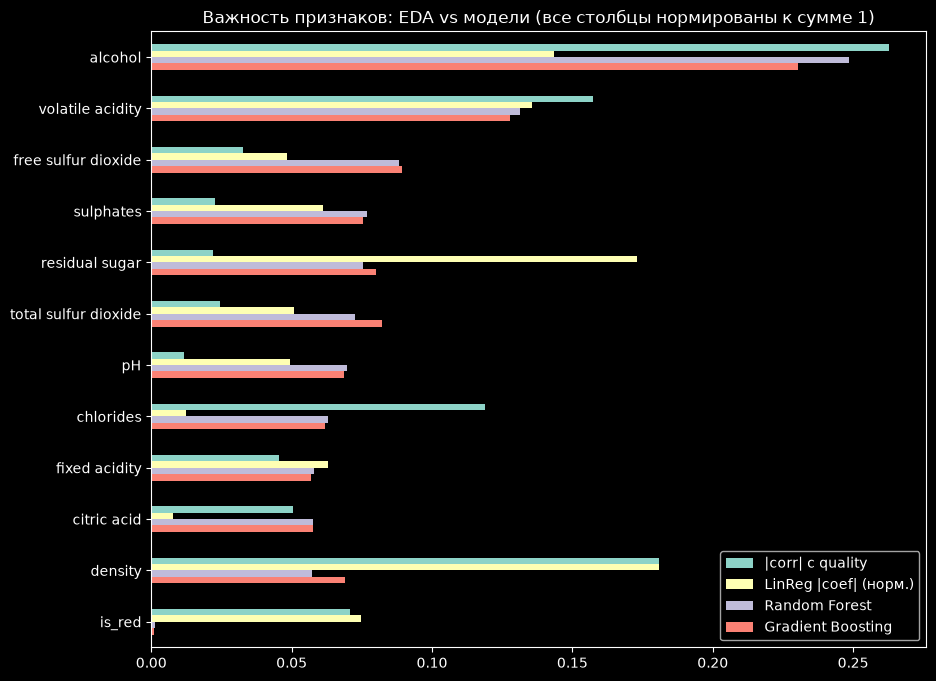

Топ-3 RF: ['alcohol', 'volatile acidity', 'free sulfur dioxide']
Топ-3 GB: ['alcohol', 'volatile acidity', 'free sulfur dioxide']


In [25]:
lr_abs = coefs.abs() / coefs.abs().sum()   # нормируем |коэф.|, чтобы сравнивать в одном масштабе
importance = pd.DataFrame({
    "|corr| с quality": corr_with_target.abs() / corr_with_target.abs().sum(),
    "LinReg |coef| (норм.)": lr_abs,
    "Random Forest": rf_imp,
    "Gradient Boosting": gb_imp,
}).sort_values("Random Forest", ascending=False)
print(importance.round(3))

importance.plot(kind="barh", figsize=(10, 8)).invert_yaxis()
plt.title("Важность признаков: EDA vs модели (все столбцы нормированы к сумме 1)"); plt.show()

print("Топ-3 RF:", list(rf_imp.sort_values(ascending=False).index[:3]))
print("Топ-3 GB:", list(gb_imp.sort_values(ascending=False).index[:3]))

**Выводы:**
1. **`alcohol` — самый важный признак во всех подходах** (корреляция, лес, бустинг), и один из главных в линейной модели.
2. **`volatile acidity`** — второй по важности у обоих ансамблей и третий по корреляции. Результаты EDA подтвердились.
3. **`density`**: в EDA и линейной регрессии — один из главных, в деревьях — среди наименее важных. Это классический пример того, как коррелированный признак «перехватывает» или «отдаёт» важность: информация в нём почти та же, что в `alcohol` + `residual sugar`.
4. **`free sulfur dioxide`, `sulphates`**: почти нулевая линейная корреляция, но заметная важность у деревьев — признак **нелинейной** связи.
5. **`is_red`** почти не важен для деревьев: тип вина модели и так восстанавливают по химии.

**Можно ли по feature importance утверждать, что изменение признака — *причина* изменения качества?** **Нет.**
- Feature importance показывает, насколько признак *помогает модели предсказывать*, т.е. отражает **корреляцию/ассоциацию в данных**, а не причинно-следственную связь.
- Возможны скрытые общие причины: например, и высокая крепость, и высокая оценка могут быть следствием хорошего урожая/спелого винограда. Если просто добавить спирта в плохое вино, оно не станет лучше.
- При коррелированных признаках важность произвольно делится между ними (пример `density`/`alcohol`), так что даже *величина* важности не однозначна.
- Impurity-based importance к тому же смещена в пользу признаков с большим числом уникальных значений.
- Для причинных выводов нужен контролируемый эксперимент (меняем один фактор при прочих равных), а не наблюдательные данные.

## 10. Анализ ошибок лучшей модели

Лучшая модель выбирается по RMSE из итоговой таблицы. Ошибку считаем как `остаток = y_true − y_pred` (положительный → модель недооценила вино).

Лучшая модель: Gradient Boosting


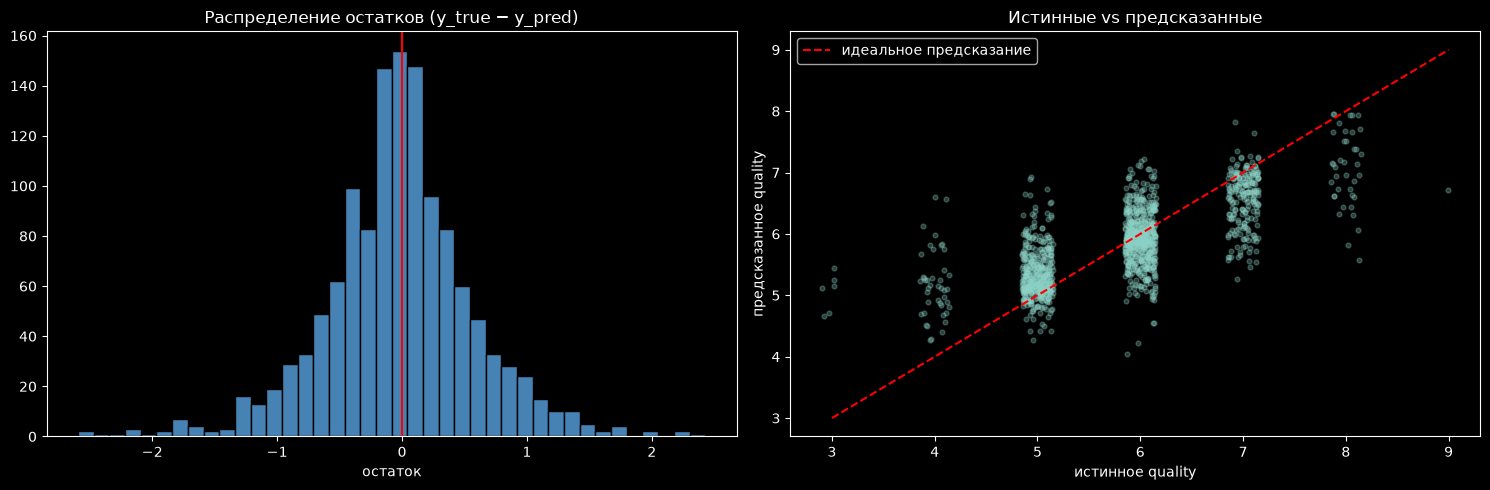

Доля объектов с |ошибкой| < 0.5: 0.673
Доля объектов с |ошибкой| > 1.0: 0.097


In [26]:
model_preds = {"Random Forest": y_pred_rf, "Gradient Boosting": y_pred_gb, "Linear Regression": y_pred_lr,
               "Linear Regression (улучшенная)": y_pred_lr_best}
best_name = results_df.drop(index="Baseline (mean)")["RMSE"].idxmin()
best_pred = model_preds[best_name]
print("Лучшая модель:", best_name)

err = pd.DataFrame({"y_true": y_test.values, "y_pred": best_pred}, index=y_test.index)
err["residual"] = err["y_true"] - err["y_pred"]
err["abs_error"] = err["residual"].abs()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].hist(err["residual"], bins=40, color="steelblue", edgecolor="black")
axes[0].axvline(0, color="red"); axes[0].set_title("Распределение остатков (y_true − y_pred)")
axes[0].set_xlabel("остаток")

jitter = np.random.uniform(-0.15, 0.15, len(err))
axes[1].scatter(err["y_true"] + jitter, err["y_pred"], alpha=0.3, s=12)
axes[1].plot([3, 9], [3, 9], "r--", label="идеальное предсказание")
axes[1].set_xlabel("истинное quality"); axes[1].set_ylabel("предсказанное quality")
axes[1].set_title("Истинные vs предсказанные"); axes[1].legend()
plt.tight_layout(); plt.show()

print("Доля объектов с |ошибкой| < 0.5:", round((err["abs_error"] < 0.5).mean(), 3))
print("Доля объектов с |ошибкой| > 1.0:", round((err["abs_error"] > 1.0).mean(), 3))

**Выводы:**
- Остатки сосредоточены около нуля, распределение близко к симметричному, но с «хвостами» — редкие крупные ошибки.
- Большая часть объектов предсказывается с ошибкой меньше 0.5 балла, и только около 10% — с ошибкой больше 1 балла.
- На scatter-графике видно **«сжатие к центру»**: для вин с quality 3–4 предсказания завышены, а для 8–9 — занижены. Точки «лежат» более полого, чем красная диагональ.

          n  mean_pred  mean_residual    MAE   RMSE
y_true                                             
3         6      5.055         -2.055  2.055  2.074
4        43      5.183         -1.183  1.183  1.303
5       428      5.343         -0.343  0.394  0.529
6       567      5.936          0.064  0.346  0.453
7       216      6.565          0.435  0.479  0.629
8        39      7.070          0.930  0.930  1.112
9         1      6.718          2.282  2.282  2.282


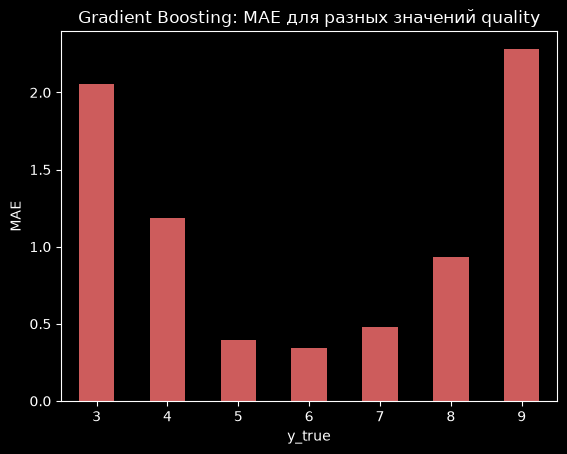

In [27]:
by_quality = err.groupby("y_true").agg(
    n=("y_true", "size"),
    mean_pred=("y_pred", "mean"),
    mean_residual=("residual", "mean"),
    MAE=("abs_error", "mean"),
    RMSE=("residual", lambda r: np.sqrt(np.mean(r ** 2))),
).round(3)
print(by_quality)

by_quality["MAE"].plot(kind="bar", color="indianred", rot=0)
plt.title(f"{best_name}: MAE для разных значений quality"); plt.ylabel("MAE"); plt.show()

**Модель работает очень неравномерно по классам:**
- На частых оценках **5 и 6** ошибка маленькая (MAE ≈ 0.3–0.4).
- На **3, 4, 8, 9** ошибка в разы больше (MAE > 1, для 3 и 9 — около 2). Средний остаток положительный у высоких оценок (модель занижает) и отрицательный у низких (завышает).

**Почему модель хуже предсказывает редкие значения quality:**
1. **Мало примеров**: вин с оценкой 3 в train ~24, с оценкой 9 — 4. Модели просто не из чего выучить, чем такие вина отличаются.
2. **Минимизация MSE** оптимизирует *среднюю* ошибку по всем объектам; выгоднее идеально предсказывать массовые 5–6, чем редкие крайности.
3. **Механика деревьев**: предсказание листа — среднее объектов в нём; редкий объект почти всегда попадает в лист вместе с «соседями» с оценками 5–6, и среднее тянется к центру. Ансамбли дополнительно усредняют много деревьев — это ещё сильнее сглаживает крайние предсказания.
4. Наконец, в train все значения в диапазоне 3–9, и деревья не могут предсказать что-то вне диапазона виденных значений, а на практике и до краёв дотягивают редко.

In [28]:
worst = err.sort_values("abs_error", ascending=False).head(10)
worst_full = worst.join(X_test)
worst_full[["y_true", "y_pred", "residual", "alcohol", "volatile acidity",
            "free sulfur dioxide", "sulphates", "residual sugar", "is_red"]].round(3)

,y_true,y_pred,residual,alcohol,volatile acidity,free sulfur dioxide,sulphates,residual sugar,is_red
6107,4,6.594,-2.594,11.5,0.260,75.0,0.38,2.6,0
5369,4,6.563,-2.563,12.0,0.270,15.0,0.65,2.4,0
1374,3,5.438,-2.438,9.8,0.815,16.0,0.51,1.2,1
3005,8,5.573,2.427,10.5,0.220,12.0,0.38,6.8,0
2426,9,6.718,2.282,12.5,0.240,27.0,0.48,2.0,0
1850,3,5.251,-2.251,9.8,0.260,41.0,0.50,16.2,0
1403,8,5.819,2.181,10.0,0.330,3.0,1.10,1.7,1
2339,3,5.152,-2.152,12.6,0.390,5.0,0.37,4.6,0
3715,4,6.135,-2.135,11.7,0.200,19.0,0.37,1.2,0
1469,3,5.116,-2.116,9.7,0.980,20.0,0.55,2.1,1


In [29]:
# Сравним самые крупные ошибки с «типичными» винами той же оценки из train
typical = pd.concat([X_train, y_train], axis=1).groupby("quality")[
    ["alcohol", "volatile acidity", "free sulfur dioxide", "sulphates", "residual sugar"]
].median().round(3)
typical

,alcohol,volatile acidity,free sulfur dioxide,sulphates,residual sugar
quality,,,,,
3,10.45,0.460,17.0,0.505,3.15
4,10.00,0.380,16.0,0.490,2.30
5,9.60,0.330,27.0,0.500,3.00
6,10.50,0.270,30.0,0.520,3.20
7,11.40,0.270,29.0,0.520,2.70
8,11.90,0.260,34.0,0.470,4.25
9,12.55,0.315,29.5,0.440,3.20


**Разбор объектов с наибольшими ошибками** (сравниваем первую таблицу с медианами по классам во второй; при `random_state=42` у вас должны получиться те же строки):
- **Все 10 самых больших ошибок — вина с крайними оценками** (3, 4, 8, 9). Ни одного вина с оценкой 5–7.
- **Переоценённые плохие вина** (строки 6107, 5369, 3715: истинная оценка 4, предсказано ≈6.1–6.6). У них `alcohol` 11.5–12% и низкая `volatile acidity` 0.20–0.27 — по двум главным признакам они выглядят как типичные вина на 7 (медианы 11.4 и 0.27). Модель «рассуждает» правильно по данным, но дефект этих вин — в том, чего нет в признаках (аромат, вкус, порча), либо это шум экспертной оценки.
- **Недооценённые хорошие вина** (строки 3005 и 1403: оценка 8, предсказано ≈5.6–5.8). Крепость всего 10–10.5% — типично для оценок 5–6, а не 8 (медиана 11.9). По химии они неотличимы от средних вин. У 1403 к тому же **экстремальные значения**: `free sulfur dioxide` = 3 (почти минимум) и `sulphates` = 1.10 (в 2 раза выше медианы) — такие сочетания в train почти не встречаются, модели не на чем было научиться.
- **Плохие вина с правильным «направлением»** (строки 1374, 1469: оценка 3, `volatile acidity` 0.8–0.98 — очень высокая). Модель заметила признак плохого вина и опустила предсказание до ≈5.1–5.4, но не до 3: вин с оценкой 3 в train всего 24, и в листьях деревьев они усредняются вместе с пятёрками.
- Вино с оценкой 9 (строка 2426) — одно из 5 во всём датасете; модель дала ≈6.7. Предсказать то, чего почти не видел, она не может.

**Итог анализа ошибок:** хорошее среднее RMSE достигается в основном за счёт массовых вин 5–6. Для практического применения (например, чтобы находить *лучшие* вина) модель недостаточно хороша. Улучшить это можно, добавив признаки (сорт, регион, год), используя веса объектов для редких классов или иную постановку задачи (например, классификация/ранжирование).

## 11. Итоговые выводы

1. Данные: 6497 вин (красные + белые), 12 признаков + `is_red`, без пропусков, ~18% дубликатов, сильный дисбаланс quality (77% — оценки 5–6).
2. Разбиение 80/20 со стратификацией по quality, `random_state=42`; все решения — по 5-fold CV на train, тест использован один раз.
3. Baseline (среднее train) — RMSE ≈ 0.87. Все модели его превзошли.
4. Линейная регрессия (RMSE ≈ 0.73) не проходит порог из-за нелинейности и разных зависимостей у красных и белых вин. С преобразованиями (Yeo-Johnson), полиномиальными признаками, Ridge и отдельными моделями по типу вина — RMSE ≈ 0.697, порог пройден впритык. На одном красном вине обычная линейная регрессия даёт ≈0.64.
5. Random Forest и Gradient Boosting — RMSE ≈ 0.60–0.61, **порог 0.70 пройден**.
6. Самые важные признаки во всех моделях — `alcohol` и `volatile acidity`; это совпадает с EDA. Feature importance — не доказательство причинности.
7. Модель хорошо предсказывает массовые оценки 5–6 и плохо — редкие 3, 4, 8, 9 (сжатие к среднему из-за малого числа примеров и минимизации MSE).